# 04 · How many guesses should we compare? (top 1 / top 3 / top 5 / likely only)

So far every "meaning" measurement compared the model's **top 5 guesses** at each noun/verb. When the model is very
sure (e.g. 90% on its #1 guess), guesses 2-5 are near-random filler and can make the spread look bigger than the
model's real uncertainty. This notebook recomputes the three meaning measurements with four guess sets:

| version | what is measured at each noun/verb |
|---|---|
| **top 1 vs real word** | distance between the model's #1 guess and the word that actually came (0 = it guessed the word) |
| **top 3 guesses** | spread of the 3 best guesses |
| **top 5 guesses** | spread of the 5 best guesses (as in notebooks 02-03) |
| **likely guesses only** | spread of only the guesses with at least **10% of the #1 guess's probability**; when only the #1 guess qualifies, the spread is **0** (the model had one candidate in mind) |

for each of: **LCA height** (WordNet), **GloVe distance**, **Qwen-embedding distance** (= 12 time series per text).

Then, for each of the 12, the same two tests as before:
1. **One number per text** (median and ups-and-downs/SD of its curve): how cleanly does it separate the kinds?
   (**pairs in order**: 100% = perfect, 50% = coin flip; **p-value** below 0.05 = unlikely to be luck)
2. **Clustering the whole curves** (DBSCAN, KMeans, DTW-KMeans, k-medoids × raw/shape-only × DTW/Euclidean, as in
   notebook 02): how many of the 25 texts end up in their own kind's cluster (best run per series)?

Reads the saved results of notebook 01 (no model run). "Guesses" are the model's best whole-word guesses of the same
part of speech as the real word, reduced to dictionary form, exactly as before.

In [1]:
import os
import sys
import warnings
from pathlib import Path

os.environ.setdefault("HF_HUB_OFFLINE", "1")
os.environ.setdefault("OMP_NUM_THREADS", "1")
warnings.filterwarnings("ignore")

# walk up from the notebook's folder until we find the repo root (the folder holding lca_core.py)
ROOT = Path.cwd()
while not (ROOT / "lca_core.py").exists():
    if ROOT == ROOT.parent:
        raise FileNotFoundError("lca_core.py not found in this folder or any parent folder")
    ROOT = ROOT.parent
HERE = ROOT / "src" / "note_books" / "Qwen7B"
sys.path.insert(0, str(ROOT))
sys.path.insert(0, str(HERE))

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display
from scipy.stats import mannwhitneyu

from lca_core import kind, load_token_embeddings
from timeseries_tools import (LIKELY_SHARE, METRIC_PREFIXES, VARIANTS, add_guess_variants, cluster_curves, curve)

RESULTS = HERE / "results"
FIG_DIR = RESULTS / "figures_variants"
FIG_DIR.mkdir(parents=True, exist_ok=True)

FACTUAL_COLOR = "#2a78d6"     # validated pair (dataviz palette check passed)
CREATIVE_COLOR = "#eb6834"
COLORS = {"factual": FACTUAL_COLOR, "creative": CREATIVE_COLOR}
INK = "#0b0b0b"
INK_SOFT = "#52514e"
GRID = "#e4e3df"
KINDS = ["factual", "creative"]


def clean_axes(ax, grid_axis="x"):
    for side in ("top", "right"):
        ax.spines[side].set_visible(False)
    for side in ("left", "bottom"):
        ax.spines[side].set_color(GRID)
    ax.tick_params(colors=INK_SOFT, labelsize=9)
    ax.grid(axis=grid_axis, color=GRID, lw=0.8)
    ax.set_axisbelow(True)


def save(fig, name, tries=3):
    # OneDrive sometimes refuses the first overwrite of a synced file (OSError 22): remove it and retry
    path = FIG_DIR / name
    for attempt in range(tries):
        try:
            fig.savefig(path, dpi=110, bbox_inches="tight")
            return
        except OSError:
            if attempt == tries - 1:
                print(f"could not save {name} (file locked?)")
                return
            path.unlink(missing_ok=True)


text_names = sorted(path.stem for path in (RESULTS / "words").glob("*.csv"))
true_kinds = np.array([kind(n) for n in text_names])
tok, E = load_token_embeddings("Qwen/Qwen2.5-7B-Instruct")
words = {}
for name in text_names:
    words[name] = add_guess_variants(pd.read_csv(RESULTS / "words" / f"{name}.csv"), tok, E)
print(len(text_names), "texts;", "per-guess probabilities available:",
      all("candidate_probs" in words[n].columns for n in text_names))

SERIES = {}
for prefix, metric in METRIC_PREFIXES.items():
    for variant, variant_title in VARIANTS.items():
        SERIES[f"{prefix}_{variant}"] = (metric, variant_title)
words[text_names[0]][["word", "candidates", "candidate_probs", "n_likely", "glove_top1", "glove_top3",
                      "glove_top5", "glove_likely"]].head(8).round(3)

25 texts; per-guess probabilities available: True


,word,candidates,candidate_probs,n_likely,glove_top1,glove_top3,glove_top5,glove_likely
0,room,item doubt quality matter man,0.0089726 0.00896603 0.0027485 0.00223382 0.00...,5,0.792,0.777,0.731,0.731
1,cried,shout reply cry yell call,0.192149 0.0413954 0.0460095 0.0251679 0.0282239,5,0.434,0.664,0.661,0.661
2,saw,see hear come find arrive,0.486356 0.0846325 0.0570328 0.0473013 0.0214369,3,-0.000,0.402,0.490,0.402
3,coming,come enter try stand look,0.0214247 0.0112287 0.00287551 0.00218771 0.00...,4,0.000,0.528,0.558,0.576
4,plenty,plenty room nobody space heap,0.00417309 0.00150861 0.000408109 0.000131941 ...,2,0.000,0.641,0.783,0.635
5,room,room space time place elbow,0.995692 0.000239894 8.08862e-06 5.71918e-06 1...,1,0.000,0.608,0.702,0.000
6,sat,sit walk march jump dance,0.351857 0.165841 0.149079 0.0409595 0.0309088,4,0.000,0.709,0.734,0.725
7,arm,arm armour square cloth chair,0.000131745 4.88465e-06 4.18696e-06 3.77682e-0...,1,0.000,0.884,0.840,0.000


## 1. How many guesses does the model really consider?
For every noun/verb: how many of the 5 guesses reach 10% of the #1 guess's probability. **1 = the model had a single
candidate in mind**; 5 = it was torn between all five. Also: how often the model's #1 guess **was** the real word.

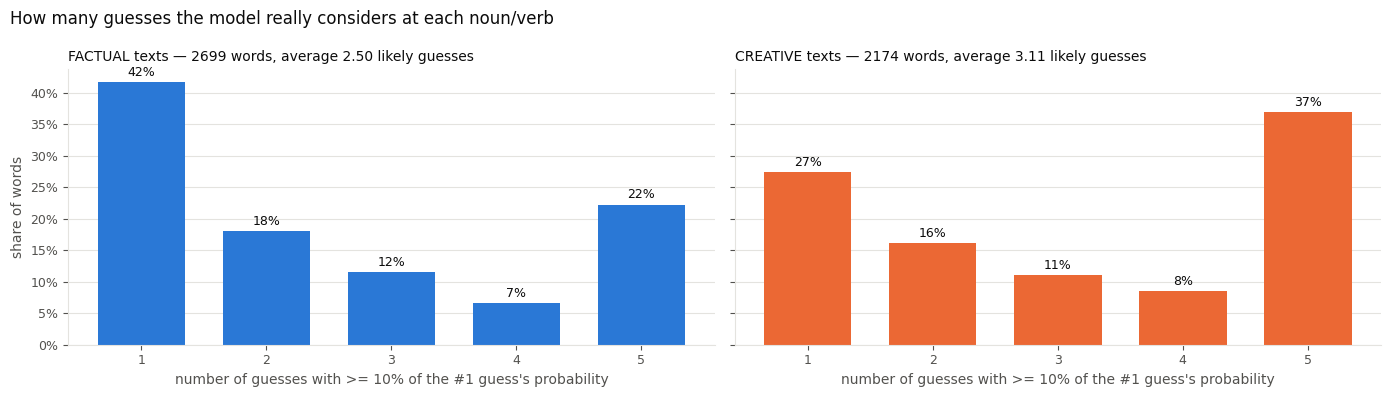

kind,factual,creative
likely guesses,,
1,41.6%,27.4%
2,18.0%,16.1%
3,11.5%,11.1%
4,6.6%,8.5%
5,22.2%,36.9%


kind,#1 guess was the real word
factual,52.9%
creative,41.3%


In [2]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4), sharey=True)
count_rows = []
for ax, kind_name in zip(axes, KINDS):
    counts = pd.concat([words[n]["n_likely"] for n in text_names if kind(n) == kind_name]).dropna().astype(int)
    shares = counts.value_counts(normalize=True).reindex(range(1, 6), fill_value=0)
    bars = ax.bar(shares.index, shares.values, color=COLORS[kind_name], width=0.7)
    for bar, share in zip(bars, shares.values):
        ax.text(bar.get_x() + bar.get_width() / 2, share + 0.01, f"{share:.0%}", ha="center", fontsize=9, color=INK)
    ax.set_title(f"{kind_name.upper()} texts — {len(counts)} words, average {counts.mean():.2f} likely guesses",
                 loc="left", fontsize=10, color=INK)
    ax.set_xticks(range(1, 6))
    ax.set_xlabel(f"number of guesses with >= {LIKELY_SHARE:.0%} of the #1 guess's probability", color=INK_SOFT)
    clean_axes(ax, grid_axis="y")
    ax.yaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: f"{v:.0%}"))
    for count, share in shares.items():
        count_rows.append({"kind": kind_name, "likely guesses": count, "share of words": share})
axes[0].set_ylabel("share of words", color=INK_SOFT)
fig.suptitle("How many guesses the model really considers at each noun/verb", x=0.01, ha="left", fontsize=12,
             color=INK)
fig.tight_layout()
save(fig, "1_likely_guess_counts.png")
plt.show()

table = pd.DataFrame(count_rows).pivot(index="likely guesses", columns="kind", values="share of words")[KINDS]
hit_rows = []
for kind_name in KINDS:
    tables = [words[n] for n in text_names if kind(n) == kind_name]
    hits = pd.concat([t["lca_top1"] == 0 for t in tables])
    hit_rows.append({"kind": kind_name, "#1 guess was the real word": hits.mean()})
display(table.style.format("{:.1%}"))
pd.DataFrame(hit_rows).style.format({"#1 guess was the real word": "{:.1%}"}).hide(axis="index")

## 2. One number per text: which version separates factual from creative best?
For each of the 12 series, every text gets two numbers from its curve: its **median** and its **ups and downs (SD)**.
The bars show **pairs in order** for each (100% = that number alone separates the two kinds perfectly; 50% = coin
flip). Exact medians and p-values are in the table below.

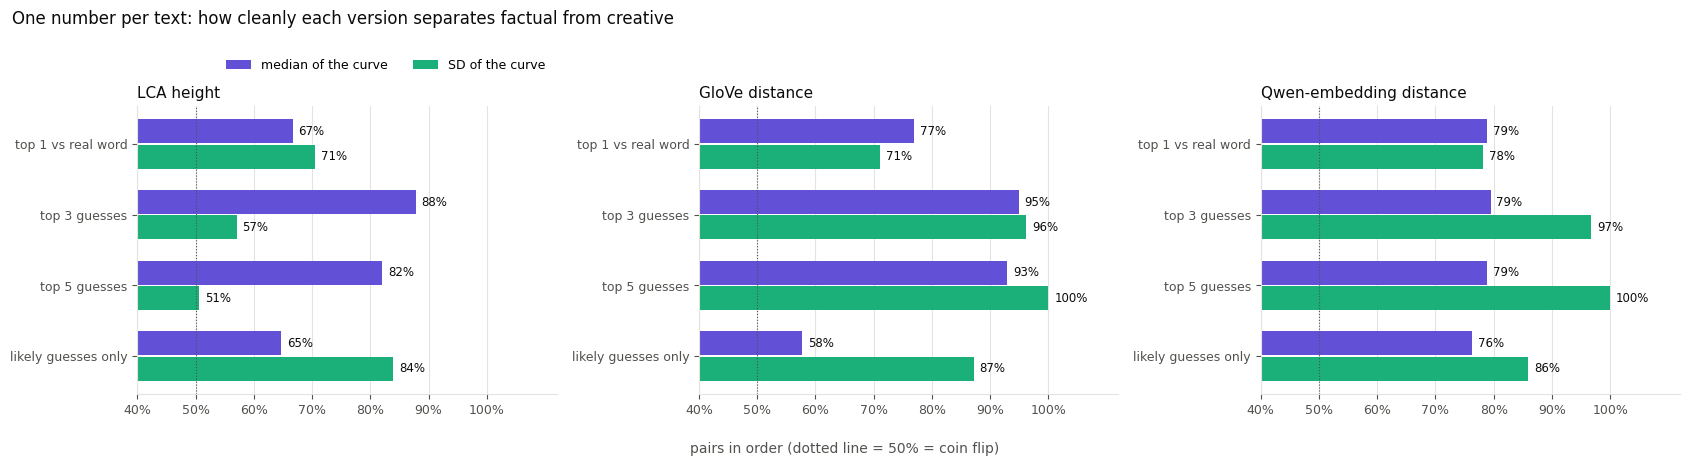

measurement,version,number,factual median,creative median,who is higher,pairs in order,p-value
Qwen-embedding distance,top 5 guesses,SD,0.036,0.042,creative higher,100%,0.0000
GloVe distance,top 5 guesses,SD,0.089,0.127,creative higher,100%,0.0000
Qwen-embedding distance,top 3 guesses,SD,0.051,0.058,creative higher,97%,0.0001
GloVe distance,top 3 guesses,SD,0.114,0.149,creative higher,96%,0.0001
GloVe distance,top 3 guesses,median,0.744,0.678,factual higher,95%,0.0002
GloVe distance,top 5 guesses,median,0.755,0.693,factual higher,93%,0.0003
LCA height,top 3 guesses,median,5.000,4.000,factual higher,88%,0.0001
GloVe distance,likely guesses only,SD,0.361,0.315,factual higher,87%,0.0018
Qwen-embedding distance,likely guesses only,SD,0.441,0.387,factual higher,86%,0.0025
LCA height,likely guesses only,SD,2.927,2.585,factual higher,84%,0.0043


In [3]:
def separation(values_factual, values_creative):
    factual_higher = (values_factual[:, None] > values_creative[None, :]).mean()
    factual_lower = (values_factual[:, None] < values_creative[None, :]).mean()
    p_value = mannwhitneyu(values_factual, values_creative).pvalue
    if factual_higher >= factual_lower:
        return factual_higher, p_value, "factual higher"
    return factual_lower, p_value, "creative higher"


separation_rows = []
for column, (metric, variant_title) in SERIES.items():
    for statistic in ["median", "SD"]:
        values = {}
        for kind_name in KINDS:
            per_text = []
            for name in text_names:
                if kind(name) != kind_name:
                    continue
                values_of_text = curve(words[name], column)
                per_text.append(np.median(values_of_text) if statistic == "median" else values_of_text.std())
            values[kind_name] = np.array(per_text)
        in_order, p_value, direction = separation(values["factual"], values["creative"])
        separation_rows.append({"measurement": metric, "version": variant_title, "number": statistic,
                                "factual median": np.median(values["factual"]),
                                "creative median": np.median(values["creative"]),
                                "who is higher": direction, "pairs in order": in_order, "p-value": p_value})
separations = pd.DataFrame(separation_rows)

variant_titles = list(VARIANTS.values())
fig, axes = plt.subplots(1, len(METRIC_PREFIXES), figsize=(17, 4.6), sharex=True)
for ax, metric in zip(axes, METRIC_PREFIXES.values()):
    rows = separations[separations["measurement"] == metric]
    y = np.arange(len(variant_titles))[::-1]
    for offset, statistic, shade in [(0.18, "median", "#6250d6"), (-0.18, "SD", "#1baf7a")]:
        values = [rows[(rows["version"] == v) & (rows["number"] == statistic)]["pairs in order"].iloc[0]
                  for v in variant_titles]
        ax.barh(y + offset, values, height=0.34, color=shade, label=f"{statistic} of the curve")
        for position, value in zip(y + offset, values):
            ax.text(value + 0.01, position, f"{value:.0%}", va="center", fontsize=8.5, color=INK)
    ax.axvline(0.5, color=INK_SOFT, lw=0.8, ls=":")
    ax.set_yticks(y, variant_titles, fontsize=9)
    ax.set_xlim(0.4, 1.12)
    ax.set_xticks([0.4, 0.5, 0.6, 0.7, 0.8, 0.9, 1.0])
    ax.xaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: f"{v:.0%}"))
    ax.set_title(metric, loc="left", fontsize=11, color=INK)
    clean_axes(ax)
axes[0].legend(frameon=False, loc="lower right", bbox_to_anchor=(1.0, 1.08), ncol=2, fontsize=9)
fig.supxlabel("pairs in order (dotted line = 50% = coin flip)", color=INK_SOFT, fontsize=10)
fig.suptitle("One number per text: how cleanly each version separates factual from creative", x=0.01, ha="left",
             fontsize=12, color=INK)
fig.tight_layout()
save(fig, "2_one_number_per_text.png")
plt.show()

separations.sort_values("pairs in order", ascending=False).style.format(
    {"factual median": "{:.3f}", "creative median": "{:.3f}", "pairs in order": "{:.0%}", "p-value": "{:.4f}"}
).hide(axis="index")

## 3. Clustering the whole curves: how many texts are sorted correctly?
For each of the 12 series, all 16 clustering runs of notebook 02 (4 methods × raw/shape-only × DTW/Euclidean); shown
is the **best run** of each. Blue = factual texts sorted correctly (out of 12), orange = creative (out of 13).

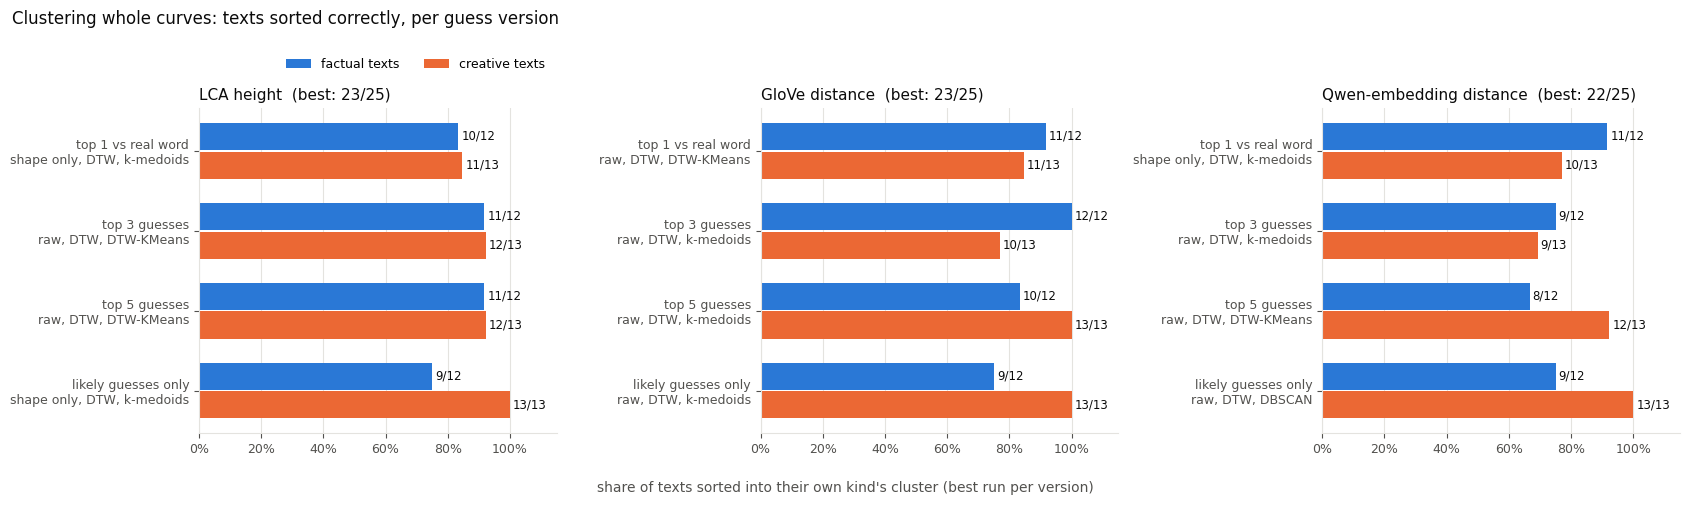

measurement,version,sorted correctly,factual correct,creative correct,ARI,scaling,distance,method
GloVe distance,likely guesses only,22,9,13,0.56,raw,DTW,k-medoids
GloVe distance,top 1 vs real word,22,11,11,0.56,raw,DTW,DTW-KMeans
GloVe distance,top 3 guesses,22,12,10,0.56,raw,DTW,k-medoids
GloVe distance,top 5 guesses,23,10,13,0.69,raw,DTW,k-medoids
LCA height,likely guesses only,22,9,13,0.56,standardised,DTW,k-medoids
LCA height,top 1 vs real word,21,10,11,0.44,standardised,DTW,k-medoids
LCA height,top 3 guesses,23,11,12,0.69,raw,DTW,DTW-KMeans
LCA height,top 5 guesses,23,11,12,0.69,raw,DTW,DTW-KMeans
Qwen-embedding distance,likely guesses only,22,9,13,0.56,raw,DTW,DBSCAN
Qwen-embedding distance,top 1 vs real word,21,11,10,0.44,standardised,DTW,k-medoids


In [4]:
cluster_rows = []
for column, (metric, variant_title) in SERIES.items():
    curves = [curve(words[n], column) for n in text_names]
    for run in cluster_curves(curves, true_kinds):
        run = dict(run)
        run.pop("labels")
        cluster_rows.append({"measurement": metric, "version": variant_title, **run})
clusterings = pd.DataFrame(cluster_rows)
best = (clusterings.sort_values(["sorted correctly", "ARI"], ascending=False)
        .groupby(["measurement", "version"], as_index=False).first())

fig, axes = plt.subplots(1, len(METRIC_PREFIXES), figsize=(17, 5), sharex=True)
for ax, metric in zip(axes, METRIC_PREFIXES.values()):
    rows = best[best["measurement"] == metric].set_index("version").loc[variant_titles]
    y = np.arange(len(variant_titles))[::-1]
    for offset, kind_name, total in [(0.18, "factual", 12), (-0.18, "creative", 13)]:
        correct = rows[f"{kind_name} correct"].to_numpy()
        ax.barh(y + offset, correct / total, height=0.34, color=COLORS[kind_name], label=f"{kind_name} texts")
        for position, value in zip(y + offset, correct):
            ax.text(value / total + 0.01, position, f"{value}/{total}", va="center", fontsize=8.5, color=INK)
    labels = [f"{v}\n{r['scaling'].replace('standardised', 'shape only')}, {r['distance']}, {r['method']}"
              for v, (_, r) in zip(variant_titles, rows.iterrows())]
    ax.set_yticks(y, labels, fontsize=8.5)
    ax.set_xlim(0, 1.15)
    ax.set_xticks([0, 0.2, 0.4, 0.6, 0.8, 1.0])
    ax.xaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: f"{v:.0%}"))
    totals = rows["sorted correctly"].to_numpy()
    ax.set_title(f"{metric}  (best: {totals.max()}/25)", loc="left", fontsize=11, color=INK)
    clean_axes(ax)
axes[0].legend(frameon=False, loc="lower right", bbox_to_anchor=(1.0, 1.08), ncol=2, fontsize=9)
fig.supxlabel("share of texts sorted into their own kind's cluster (best run per version)", color=INK_SOFT, fontsize=10)
fig.suptitle("Clustering whole curves: texts sorted correctly, per guess version", x=0.01, ha="left", fontsize=12,
             color=INK)
fig.tight_layout()
save(fig, "3_clustering_per_version.png")
plt.show()

best[["measurement", "version", "sorted correctly", "factual correct", "creative correct", "ARI", "scaling",
      "distance", "method"]].sort_values(["measurement", "version"]).style.format({"ARI": "{:.2f}"}).hide(axis="index")

## 4. Findings

**How many guesses the model really considers** (guesses with at least 10% of the #1 guess's probability):

| | factual | creative |
|---|---|---|
| only 1 likely guess (the model is confident) | 42% of words | 27% |
| all 5 guesses are likely (the model is unsure) | 22% | 37% |
| average likely guesses | 2.50 | 3.11 |
| the #1 guess was the real word | 53% | 41% |

So the model is confident much more often on factual text. That difference is itself a signal.

**One number per text** (pairs in order: 100% = every factual text is on the right side of every creative text):

| | top 1 vs real word | top 3 | top 5 | likely only |
|---|---|---|---|---|
| GloVe, SD of the curve | 71% | 96% | **100%** | 87% (direction flips) |
| Qwen embedding, SD | 78% | 97% | **100%** | 86% (direction flips) |
| GloVe, median | 77% | **95%** | 93% | 58% |
| LCA height, median | 67% | **88%** | 82% | 65% |
| LCA height, SD | 71% | 57% | 51% | **84%** (direction flips) |

- **Top 5 is not too many.** For the GloVe and Qwen-embedding ups and downs (SD), top 5 is the only version that
  puts all 12 factual texts below all 13 creative ones. Top 3 comes close (96–97%).
- **Top 3 helps LCA a little:** the median LCA height separates 88% of pairs with top 3 vs 82% with top 5.
- **Top 1 vs the real word is weaker (67–79%).** Its median is 0 for factual texts (the #1 guess was usually right)
  and above 0 for creative ones, but a single guess is a noisy measure.
- **Likely guesses only measures something else.** Confident words become 0, so the curve jumps between 0 and the
  spread. Factual texts have more of those zeros, so their curve swings *more*: the SD direction flips (factual
  higher). It works for LCA (84%, where the other versions fail), but less well than top 5 for GloVe and embeddings.

**Clustering whole curves** (best run per version, out of 25 texts):

| | top 1 vs real word | top 3 | top 5 | likely only |
|---|---|---|---|---|
| LCA height | 21 | **23** | **23** | 22 |
| GloVe distance | 22 | 22 | **23** | 22 |
| Qwen-embedding distance | 21 | 18 | 20 | **22** |

- Top 3 and top 5 give the same LCA result (23/25, raw DTW-KMeans).
- Top 5 stays best for GloVe (23/25, 10/12 factual, 13/13 creative).
- Likely-only sorts **all 13 creative texts correctly** for every measurement, but loses 3 factual texts.
- It is the best version for Qwen embeddings (22 vs 20 with top 5).

**Bottom line:** keep top 5 for GloVe/embedding spread. Top 3 is equally good for LCA. Likely-only is a useful
extra series (mostly for LCA and Qwen embeddings), not a replacement.